# Resolución de los sensores

La resolución de un sensor es su capacidad para discriminar información. Se describe con cuatro dimensiones independientes: espacial, espectral, radiométrica y temporal. Ningún sensor puede tener la mejor resolución en las cuatro a la vez, porque todas compiten por la misma cantidad limitada de energía que llega al detector y por la capacidad de transmitir datos a tierra; elegir un sensor es elegir un compromiso {cite}`chuvieco2008,campbell2011`.

## Resolución espacial

La resolución espacial es el tamaño del objeto más pequeño que se puede distinguir en una imagen. En un sensor electro-óptico depende del campo de visión instantáneo (IFOV), el ángulo sólido que ve un detector, y de la altura de la plataforma. El tamaño de la proyección del IFOV sobre el terreno, la distancia de muestreo en el terreno (GSD, o ground resolution cell), es aproximadamente

$$\mathrm{GSD} = H \cdot \mathrm{IFOV},$$

con el IFOV en radianes. Por ejemplo, Landsat 8 tiene un IFOV de unos 42.5 µrad y orbita a 705 km, lo que da 30 m. En la práctica la GSD coincide con el tamaño del píxel de la imagen, aunque el píxel puede remuestrearse a otro tamaño durante el procesamiento. En la película fotográfica la resolución se expresa en pares de líneas por milímetro: si el ancho de una línea más el espacio contiguo es de 0.04 mm, la película resuelve 25 pares por milímetro, y la resolución en el terreno es ese valor multiplicado por el denominador de la escala.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['figure.dpi'] = 100

for nom, H_km, ifov_urad in [('Landsat 8 OLI', 705, 42.5), ('Sentinel-2 MSI (10 m)', 786, 12.7),
                             ('MODIS (250 m)', 705, 354), ('Dron a 120 m', 0.12, 300)]:
    print(f'{nom:24s} H = {H_km:7.2f} km, IFOV = {ifov_urad:5.1f} µrad -> GSD = {H_km*1e3*ifov_urad*1e-6:8.3f} m')

Landsat 8 OLI            H =  705.00 km, IFOV =  42.5 µrad -> GSD =   29.962 m
Sentinel-2 MSI (10 m)    H =  786.00 km, IFOV =  12.7 µrad -> GSD =    9.982 m
MODIS (250 m)            H =  705.00 km, IFOV = 354.0 µrad -> GSD =  249.570 m
Dron a 120 m             H =    0.12 km, IFOV = 300.0 µrad -> GSD =    0.036 m


El tamaño del píxel controla qué rasgos geológicos son visibles. La celda siguiente genera un terreno sintético con un escarpe de falla, una red de drenaje fina y un pequeño deslizamiento, y lo muestra con píxeles de 2, 10, 30 y 90 m. El deslizamiento, de unos 60 m de ancho, desaparece en la imagen de 90 m, y los canales menores se pierden desde 30 m.

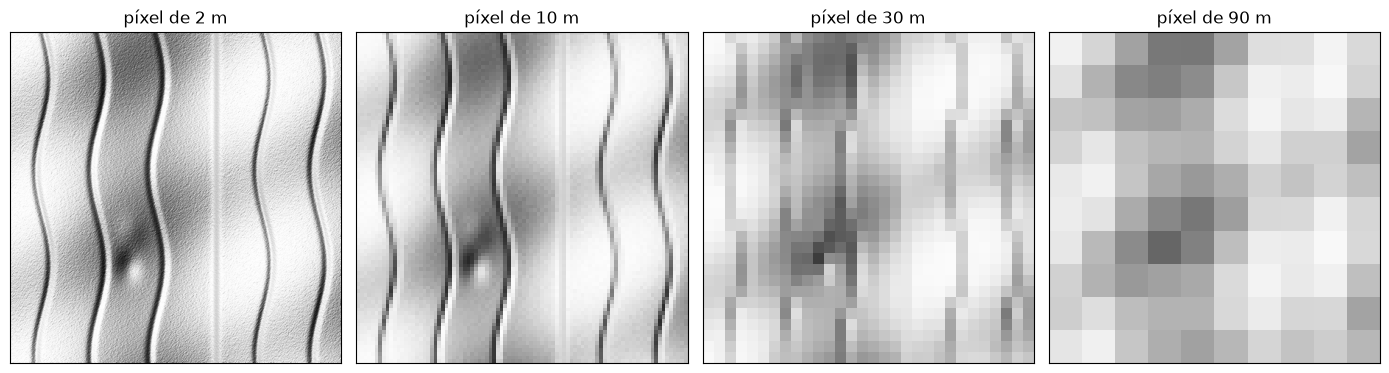

In [2]:
rng = np.random.default_rng(0)
n, dx = 450, 2.0                       # 450 x 450 celdas de 2 m = 900 m
x, y = np.meshgrid(np.arange(n) * dx, np.arange(n) * dx)
from matplotlib.colors import LightSource
z = 0.15 * y + 30 * np.sin(x / 110) + 12 * np.sin(y / 75 + x / 160)
z += 25 / (1 + np.exp(-(x - 560) / 4))                                    # escarpe de falla
for x0 in [90, 240, 400, 690, 840]:
    z -= 9 * np.exp(-((x - x0 - 20 * np.sin(y / 80))**2) / (2 * 7**2))   # canales
z -= 14 * np.exp(-(((x - 320) / 28)**2 + ((y - 640) / 40)**2))           # cicatriz de deslizamiento
z += 6 * np.exp(-(((x - 330) / 35)**2 + ((y - 540) / 45)**2))            # depósito del deslizamiento
z += rng.normal(0, 0.25, z.shape)
sombreado = LightSource(azdeg=315, altdeg=40).hillshade(z, dx=dx, dy=dx, vert_exag=2)

def degradar(img, f):
    m = img.shape[0] // f * f
    return img[:m, :m].reshape(m // f, f, m // f, f).mean(axis=(1, 3))

fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
for a, f in zip(axs, [1, 5, 15, 45]):
    a.imshow(degradar(sombreado, f), cmap='gray', vmin=0, vmax=1, extent=[0, 900, 0, 900])
    a.set_title(f'píxel de {f*dx:.0f} m'); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Escala, resolución y área mínima cartografiable

La resolución espacial de una imagen y la escala de un mapa están relacionadas. Una regla práctica atribuida a {cite:t}`tobler1987` dice que el tamaño de píxel adecuado, en metros, es el denominador de la escala dividido por 1000 y por 2; dicho de otra forma, el rasgo más pequeño que se puede representar en un mapa mide alrededor de medio milímetro sobre el papel, y el píxel debe ser la mitad de ese rasgo. Una imagen de 30 m sirve, entonces, para mapas a escala 1:60 000 o menores. Del mismo modo, el área mínima cartografiable (AMC) es el área más pequeña que vale la pena delimitar en un mapa, usualmente de 4 × 4 mm sobre el papel; para que un polígono se reconozca en una imagen debe contener varios píxeles, típicamente al menos 4 en cada dirección.

In [3]:
print(f'{"escala":>10s} {"píxel adecuado (m)":>20s} {"AMC 4x4 mm (ha)":>18s}')
for E in [5000, 10000, 25000, 50000, 100000, 250000]:
    pix = E / 1000 / 2
    amc = (4e-3 * E)**2 / 1e4
    print(f'1:{E:<8d} {pix:20.1f} {amc:18.2f}')

    escala   píxel adecuado (m)    AMC 4x4 mm (ha)
1:5000                      2.5               0.04
1:10000                     5.0               0.16
1:25000                    12.5               1.00
1:50000                    25.0               4.00
1:100000                   50.0              16.00
1:250000                  125.0             100.00


## Resolución espectral

La resolución espectral es el número de bandas y su ancho. Una fotografía pancromática tiene una sola banda ancha; Landsat 8 tiene 11 bandas; Sentinel-2, 13; los sensores hiperespectrales, como EnMAP o PRISMA, más de 200 bandas de unos 10 nm. Más bandas y más estrechas permiten reconocer rasgos de absorción diagnósticos, como los de las arcillas y los carbonatos, pero cada banda estrecha recibe menos energía, lo que obliga a píxeles más grandes o a más ruido. La celda siguiente muestra el espectro de una roca con dos absorciones en el infrarrojo de onda corta, a 2.20 µm (arcillas) y 2.33 µm (carbonatos), visto por un sensor hiperespectral, por Sentinel-2 y por un sensor de banda única.

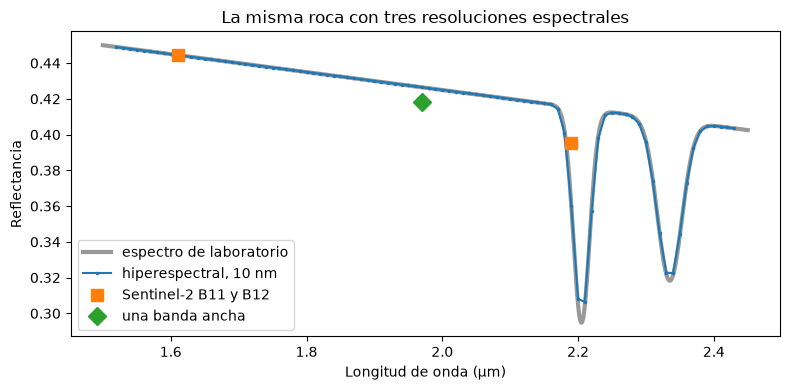

In [4]:
lam = np.linspace(1.5, 2.45, 1000)
g = lambda c, w: np.exp(-0.5 * ((lam - c) / w)**2)
espectro = 0.45 - 0.05 * (lam - 1.5) - 0.12 * g(2.205, 0.012) - 0.09 * g(2.335, 0.018)

def sensor(centros, ancho):
    return centros, [espectro[np.abs(lam - c0) <= ancho / 2].mean() for c0 in centros]

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(lam, espectro, color='0.6', lw=3, label='espectro de laboratorio')
ax.plot(*sensor(np.arange(1.52, 2.44, 0.01), 0.01), '.-', ms=3, label='hiperespectral, 10 nm')
ax.plot(*sensor([1.61, 2.19], 0.18), 's', ms=9, label='Sentinel-2 B11 y B12')
ax.plot(*sensor([1.97], 0.9), 'D', ms=9, label='una banda ancha')
ax.set_xlabel('Longitud de onda (µm)'); ax.set_ylabel('Reflectancia')
ax.legend(); ax.set_title('La misma roca con tres resoluciones espectrales'); plt.tight_layout(); plt.show()

## Resolución radiométrica

La resolución radiométrica es la sensibilidad del sensor para distinguir diferencias de energía, y se expresa como el número de bits con que se cuantifica cada medida. Con $n$ bits hay $2^n$ niveles digitales (ND): 256 con 8 bits, como en Landsat 5, 4096 con 12 bits, como en Landsat 8 y Sentinel-2, y 65 536 con 16 bits. Más niveles permiten distinguir pequeños contrastes en zonas muy oscuras, como el agua o las sombras, o muy brillantes, como la nieve, sin saturar. La celda siguiente cuantifica la misma escena con 1, 3, 5 y 8 bits.

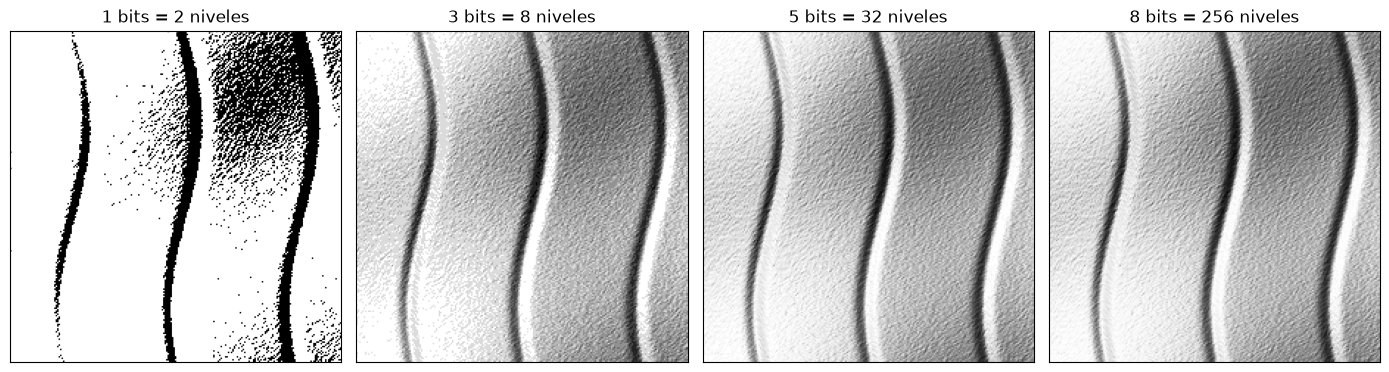

In [5]:
fig, axs = plt.subplots(1, 4, figsize=(14, 3.8))
for a, bits in zip(axs, [1, 3, 5, 8]):
    niveles = 2**bits
    q = np.floor(sombreado * (niveles - 1) + 0.5) / (niveles - 1)
    a.imshow(q[:225, :225], cmap='gray', vmin=0, vmax=1)
    a.set_title(f'{bits} bits = {niveles} niveles'); a.set_xticks([]); a.set_yticks([])
plt.tight_layout(); plt.show()

## Resolución temporal y los compromisos entre resoluciones

La resolución temporal es la frecuencia con que el sensor observa un mismo punto: 16 días para Landsat 8, 5 días para Sentinel-2, 1 a 2 días para MODIS y 10 a 15 minutos para un satélite geoestacionario. Para fenómenos rápidos, como inundaciones, incendios o la nubosidad tropical que cubre los Andes buena parte del año, la resolución temporal puede ser más importante que la espacial: con una revisita de 16 días y una probabilidad alta de nubes, pasan meses sin una imagen útil.

La figura siguiente ubica algunos sensores según su resolución espacial y temporal, y muestra el compromiso general: los sensores que ven más detalle cubren franjas más estrechas y revisitan con menos frecuencia, salvo que se usen constelaciones de muchos satélites, como PlanetScope, o sensores apuntables.

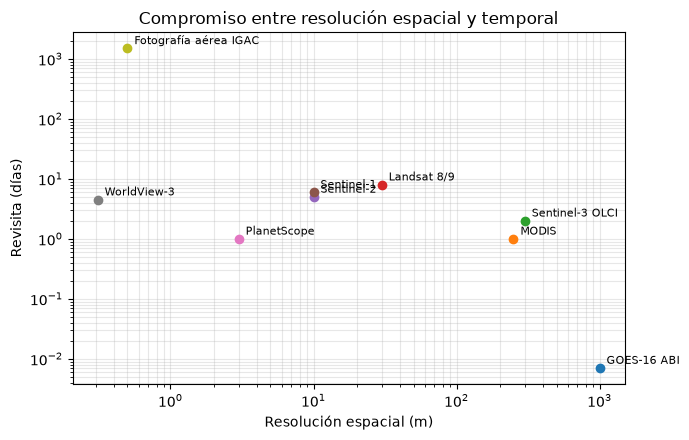

In [6]:
sens = {'GOES-16 ABI': (1000, 0.007), 'MODIS': (250, 1), 'Sentinel-3 OLCI': (300, 2), 'Landsat 8/9': (30, 8),
        'Sentinel-2': (10, 5), 'Sentinel-1': (10, 6), 'PlanetScope': (3, 1), 'WorldView-3': (0.31, 4.5),
        'Fotografía aérea IGAC': (0.5, 1500)}
fig, ax = plt.subplots(figsize=(7, 4.5))
for nom, (res, rev) in sens.items():
    ax.loglog(res, rev, 'o'); ax.annotate(nom, (res, rev), textcoords='offset points', xytext=(5, 3), fontsize=8)
ax.set_xlabel('Resolución espacial (m)'); ax.set_ylabel('Revisita (días)')
ax.set_title('Compromiso entre resolución espacial y temporal'); ax.grid(alpha=0.3, which='both')
plt.tight_layout(); plt.show()

Una última consideración práctica es el volumen de datos. Una escena crece con el cuadrado de la resolución espacial, con el número de bandas y con el número de bits, y una serie temporal la multiplica por el número de fechas. La celda siguiente lo calcula para un área de 100 × 100 km y muestra por qué el procesamiento en la nube del capítulo {doc}`14_Plataformas_EO` se volvió la norma.

In [7]:
area_km = 100
for nom, pix, bandas, bits, fechas_ano in [('Landsat 8', 30, 11, 16, 23), ('Sentinel-2', 10, 13, 16, 73),
                                           ('PlanetScope', 3, 4, 16, 365), ('Hiperespectral 30 m', 30, 230, 16, 12)]:
    n_pix = (area_km * 1e3 / pix)**2
    gb = n_pix * bandas * bits / 8 / 1e9
    print(f'{nom:20s} {gb:7.2f} GB por escena, {gb*fechas_ano:9.1f} GB por año')

Landsat 8               0.24 GB por escena,       5.6 GB por año
Sentinel-2              2.60 GB por escena,     189.8 GB por año
PlanetScope             8.89 GB por escena,    3244.4 GB por año
Hiperespectral 30 m     5.11 GB por escena,      61.3 GB por año


## Para profundizar

El capítulo 3 de {cite}`chuvieco2008` trata las cuatro resoluciones con ejemplos, y el capítulo 4 de {cite}`tempfli2009` explica la relación entre IFOV, GSD y la función de dispersión de punto del sensor, que hace que el detalle real de una imagen sea algo menor que el tamaño del píxel.